# TP1 — Premier pipeline et première fuite

**Cours :** Introduction au Machine Learning — 60 h — Master 1 SDIA
**Enseignante :** Dr. Noulapeu Ngaffo Armielle — ENSPD, Université de Douala
**Durée conseillée :** 2 h · **Barème :** 10 points

---

## Objectifs

- Charger des données réelles et les découper.
- Comparer un modèle à une baseline.
- Lire une matrice de confusion et une validation croisée.
- Fabriquer et mesurer une fuite de données.

## Travail demandé

1. Répondre aux 3 questions de la section « À vous ».
2. Rendre le notebook exécuté.

## Mode d'emploi

- Exécuter les cellules dans l'ordre ; tout tourne sur CPU en moins d'une minute.
- Les cellules **« À vous »** sont évaluées. Graine fixée : deux exécutions
  donnent le même résultat.

In [1]:
%matplotlib inline
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
np.random.seed(4112)
print('environnement pret')

environnement pret


## 1. Les données

Jeu **breast_cancer** (fourni avec scikit-learn, aucun téléchargement) :
569 patients, 30 mesures, étiquette bénin / malin.

In [2]:
from sklearn.datasets import load_breast_cancer
X, y = load_breast_cancer(return_X_y=True, as_frame=True)
print("formes :", X.shape, "| etiquettes :", y.shape)
print("repartition :", y.value_counts().to_dict())
X.head(3)

formes : (569, 30) | etiquettes : (569,)
repartition : {1: 357, 0: 212}


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.8,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.8,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.0,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.5,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758


## 2. Découpage : entraînement et test

In [3]:
from sklearn.model_selection import train_test_split
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=4112, stratify=y)
print("entrainement :", Xtr.shape, "| test :", Xte.shape)

entrainement : (426, 30) | test : (143, 30)


## 3. La baseline : sans elle, aucun score n'est interprétable

In [4]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score
base = DummyClassifier(strategy="most_frequent").fit(Xtr, ytr)
acc_base = accuracy_score(yte, base.predict(Xte))
print(f"baseline (classe majoritaire) : {acc_base:.3f}")

baseline (classe majoritaire) : 0.629


## 4. Un premier vrai modèle, dans un pipeline

In [5]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

modele = Pipeline([("scaler", StandardScaler()),
                   ("clf", LogisticRegression(max_iter=1000))])
modele.fit(Xtr, ytr)
acc = accuracy_score(yte, modele.predict(Xte))
print(f"regression logistique : {acc:.3f}")
print(f"gain sur la baseline  : {100*(acc-acc_base):.1f} points")

regression logistique : 0.979
gain sur la baseline  : 35.0 points


## 5. Au-delà de l'exactitude : la matrice de confusion

In [6]:
from sklearn.metrics import confusion_matrix, classification_report
pred = modele.predict(Xte)
cm = confusion_matrix(yte, pred)
print("matrice de confusion :")
print(pd.DataFrame(cm, index=["reel benin", "reel malin"],
                   columns=["predit benin", "predit malin"]))
print()
print(classification_report(yte, pred, target_names=["benin", "malin"]))

matrice de confusion :
            predit benin  predit malin
reel benin            52             1
reel malin             2            88

              precision    recall  f1-score   support

       benin       0.96      0.98      0.97        53
       malin       0.99      0.98      0.98        90

    accuracy                           0.98       143
   macro avg       0.98      0.98      0.98       143
weighted avg       0.98      0.98      0.98       143



## 6. Validation croisée : un score, mais avec son incertitude

Un score unique cache l'instabilité. On rapporte **moyenne ± écart-type**.

In [7]:
from sklearn.model_selection import cross_val_score
scores = cross_val_score(modele, Xtr, ytr, cv=5, scoring="accuracy")
print("scores par pli :", np.round(scores, 3))
print(f"moyenne : {scores.mean():.3f}  ecart-type : {scores.std():.3f}")

scores par pli : [0.965 1.    0.965 0.976 0.965]
moyenne : 0.974  ecart-type : 0.014


## 7. Fabriquer une fuite, et la mesurer

On ajoute **300 variables de pur bruit** et on tire les étiquettes au hasard :
il n'y a rien à apprendre. Pourtant, une sélection de variables faite *avant*
la validation croisée produit un score flatteur.

In [8]:
from sklearn.feature_selection import SelectKBest, f_classif
rng = np.random.default_rng(4112)
n, p, k = 90, 600, 10
Xb = rng.normal(size=(n, p))
yb = rng.integers(0, 2, n)          # etiquettes aleatoires

# (a) FUITE : selection sur tout le jeu, puis validation croisee
sel = SelectKBest(f_classif, k=k).fit(Xb, yb)
score_fuite = cross_val_score(LogisticRegression(max_iter=1000),
                              sel.transform(Xb), yb, cv=5).mean()

# (b) PROPRE : la selection vit dans le pipeline
propre = Pipeline([("sel", SelectKBest(f_classif, k=k)),
                   ("clf", LogisticRegression(max_iter=1000))])
score_propre = cross_val_score(propre, Xb, yb, cv=5).mean()

print(f"avec fuite : {score_fuite:.3f}")
print(f"propre     : {score_propre:.3f}")
print(f"ecart      : {100*(score_fuite-score_propre):.1f} points")

avec fuite : 0.733
propre     : 0.522
ecart      : 21.1 points


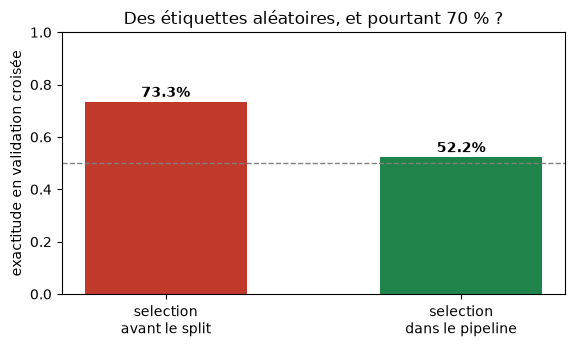

In [9]:
plt.figure(figsize=(6.5, 3.4))
b = plt.bar(["selection\navant le split", "selection\ndans le pipeline"],
            [score_fuite, score_propre], color=["#C0392B", "#1E8449"], width=.55)
plt.axhline(.5, color="grey", ls="--", lw=1)
for bb, v in zip(b, [score_fuite, score_propre]):
    plt.text(bb.get_x()+bb.get_width()/2, v+.02, f"{v:.1%}", ha="center", fontweight="bold")
plt.ylim(0, 1); plt.ylabel("exactitude en validation croisée")
plt.title("Des étiquettes aléatoires, et pourtant 70 % ?")
plt.show()

## 8. À vous (noté)

**1.** Remplacez la régression logistique par un `RandomForestClassifier`
       (`n_estimators=200, random_state=4112`). La baseline change-t-elle ?
       Le gain est-il plus grand ?

**2.** Le jeu est-il déséquilibré ? Regardez `y.value_counts()` : quel serait
       le danger de juger avec l'exactitude seule ?

**3.** Dans la section 7, expliquez en deux phrases **pourquoi** la sélection
       faite avant le split fabrique un score élevé alors que les étiquettes
       sont aléatoires.

In [10]:
# ---- A VOUS ----
# 1)

# 2)

# 3) reponse :

## 9. Ce qu'il faut retenir

| Geste | Pourquoi |
|---|---|
| baseline d'abord | sans référence, un score ne veut rien dire |
| pipeline | le prétraitement ne doit jamais voir le test |
| validation croisée | un score seul cache l'instabilité |
| plusieurs métriques | l'exactitude masque les classes rares |